# Initialization

## Imports

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Variables

In [2]:
DATA_PATH = Path("../data")
RECIPES_PATH = f"{DATA_PATH}/raw/RAW_recipes.csv"
INTERACTIONS_PATH = f"{DATA_PATH}/raw/RAW_interactions.csv"

## Functions

In [3]:
def summarize_pdf(
    pdf: pd.DataFrame,
    shape_flag=1,
    memory_flag=0,
    columns_flag=0,
    stats_flag=0,
    display_flag=1,
    n=3,
    ) -> None:
    if shape_flag:
        print(f"Shape: {pdf.shape}")
    if memory_flag:
        print(f"Memory usage: {pdf.memory_usage(deep=True).sum() / 1024**2:.2f} MB")

    if columns_flag:
        print("\nColumn Summary:")
        display(pd.DataFrame({
            "dtype": pdf.dtypes,
            "non_null": pdf.notna().sum(),
            "null": pdf.isna().sum(),
            "null_pct": pdf.isna().mean().mul(100).round(2),
            "unique": pdf.nunique(dropna=True),
        }))

    if stats_flag:
        print("\nDescriptive Statistics:")
        display(pdf.describe(include="all").T)

    if display_flag:
        print("\nDataframe:")
        display(pdf.head(n=n))

# Load data

In [4]:
recipes = pd.read_csv(RECIPES_PATH)
summarize_pdf(recipes, shape_flag=1, memory_flag=1, columns_flag=1, stats_flag=1, display_flag=1, n=3)

Shape: (231637, 12)
Memory usage: 358.05 MB

Column Summary:


,dtype,non_null,null,null_pct,unique
name,object,231636,1,0.00,230185
id,int64,231637,0,0.00,231637
minutes,int64,231637,0,0.00,888
contributor_id,int64,231637,0,0.00,27926
submitted,object,231637,0,0.00,5090
tags,object,231637,0,0.00,209115
nutrition,object,231637,0,0.00,229318
n_steps,int64,231637,0,0.00,94
steps,object,231637,0,0.00,231074
description,object,226658,4979,2.15,222668



Descriptive Statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
name,231636,230185,crock pot lemon garlic chicken,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
id,231637.0,NaN,NaN,NaN,222014.708984,141206.635626,38.0,99944.0,207249.0,333816.0,537716.0
minutes,231637.0,NaN,NaN,NaN,9398.546009,4461963.03886,0.0,20.0,40.0,65.0,2147483647.0
contributor_id,231637.0,NaN,NaN,NaN,5534885.113838,99791408.213902,27.0,56905.0,173614.0,398275.0,2002289981.0
submitted,231637,5090,2000-03-06,470,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tags,231637,209115,"['15-minutes-or-less', 'time-to-make', 'course...",397,NaN,NaN,NaN,NaN,NaN,NaN,NaN
nutrition,231637,229318,"[69.4, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]",36,NaN,NaN,NaN,NaN,NaN,NaN,NaN
n_steps,231637.0,NaN,NaN,NaN,9.765499,5.995128,0.0,6.0,9.0,12.0,145.0
steps,231637,231074,['blend all ingredients until smooth'],20,NaN,NaN,NaN,NaN,NaN,NaN,NaN
description,226658,222668,yum,153,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Dataframe:


,name,id,minutes,contributor_id,submitted,tags,nutrition,n_steps,steps,description,ingredients,n_ingredients
0,arriba baked winter squash mexican style,137739,55,47892,2005-09-16,"['60-minutes-or-less', 'time-to-make', 'course...","[51.5, 0.0, 13.0, 0.0, 2.0, 0.0, 4.0]",11,"['make a choice and proceed with recipe', 'dep...",autumn is my favorite time of year to cook! th...,"['winter squash', 'mexican seasoning', 'mixed ...",7
1,a bit different breakfast pizza,31490,30,26278,2002-06-17,"['30-minutes-or-less', 'time-to-make', 'course...","[173.4, 18.0, 0.0, 17.0, 22.0, 35.0, 1.0]",9,"['preheat oven to 425 degrees f', 'press dough...",this recipe calls for the crust to be prebaked...,"['prepared pizza crust', 'sausage patty', 'egg...",6
2,all in the kitchen chili,112140,130,196586,2005-02-25,"['time-to-make', 'course', 'preparation', 'mai...","[269.8, 22.0, 32.0, 48.0, 39.0, 27.0, 5.0]",6,"['brown ground beef in large pot', 'add choppe...",this modified version of 'mom's' chili was a h...,"['ground beef', 'yellow onions', 'diced tomato...",13


In [5]:
interactions = pd.read_csv(INTERACTIONS_PATH)
summarize_pdf(interactions, shape_flag=1, memory_flag=1, columns_flag=1, stats_flag=1, display_flag=1, n=3)


Shape: (1132367, 5)
Memory usage: 445.34 MB

Column Summary:


,dtype,non_null,null,null_pct,unique
user_id,int64,1132367,0,0.00,226570
recipe_id,int64,1132367,0,0.00,231637
date,object,1132367,0,0.00,6396
rating,int64,1132367,0,0.00,6
review,object,1132198,169,0.01,1125282



Descriptive Statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
user_id,1132367.0,NaN,NaN,NaN,138429067.430652,501426863.683784,1533.0,135470.0,330937.0,804550.0,2002372706.0
recipe_id,1132367.0,NaN,NaN,NaN,160897.208164,130398.719639,38.0,54257.0,120547.0,243852.0,537716.0
date,1132367,6396,2008-01-27,723,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rating,1132367.0,NaN,NaN,NaN,4.411016,1.264752,0.0,4.0,5.0,5.0,5.0
review,1132198,1125282,Delicious!,309,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Dataframe:


,user_id,recipe_id,date,rating,review
0,38094,40893,2003-02-17,4,Great with a salad. Cooked on top of stove for...
1,1293707,40893,2011-12-21,5,"So simple, so delicious! Great for chilly fall..."
2,8937,44394,2002-12-01,4,This worked very well and is EASY. I used not...


## Data Quality Audit

Before cleaning the data, we inspect missing values,
duplicate records, rating validity, recipe identifiers,
and potential outliers.

These checks will inform our cleaning decisions
and the definition of a valid rating.

In [6]:
quality_checks = pd.Series({
    "duplicate_recipe_ids": recipes["id"].duplicated().sum(),
    "duplicate_interaction_rows": interactions.duplicated().sum(),
    "repeated_user_recipe_pairs": interactions.duplicated(
        subset=["user_id", "recipe_id"]
    ).sum(),
    "interactions_with_unknown_recipe_ids": (
        ~interactions["recipe_id"].isin(recipes["id"])
    ).sum(),
    "missing_ratings": interactions["rating"].isna().sum(),
    "zero_ratings": interactions["rating"].eq(0).sum(),
    "ratings_outside_0_to_5": (
        interactions["rating"].notna()
        & ~interactions["rating"].between(0, 5)
    ).sum(),
    "missing_recipe_names": recipes["name"].isna().sum(),
    "nonpositive_preparation_times": recipes["minutes"].le(0).sum(),
    "preparation_times_at_least_24_hours": (
        recipes["minutes"].ge(24 * 60).sum()
    ),
})

summarize_pdf(quality_checks.to_frame(name="count"), n=100)
summarize_pdf(
    interactions
    .loc[
        interactions["rating"].eq(0),
        [
            "user_id",
            "recipe_id",
            "date",
            "rating",
            "review",
            ],
    ],
    n=10
)


Shape: (10, 1)

Dataframe:


,count
duplicate_recipe_ids,0
duplicate_interaction_rows,0
repeated_user_recipe_pairs,0
interactions_with_unknown_recipe_ids,0
missing_ratings,0
zero_ratings,60847
ratings_outside_0_to_5,0
missing_recipe_names,1
nonpositive_preparation_times,1094
preparation_times_at_least_24_hours,2121


Shape: (60847, 5)

Dataframe:


,user_id,recipe_id,date,rating,review
6,124416,120345,2011-08-06,0,"Just an observation, so I will not rate. I fo..."
12,468945,134728,2008-02-20,0,Made my own buttermilk w/ vinegar and milk. U...
23,681408,225241,2008-03-14,0,This is a very good recipe. We also want to c...
39,2002068522,29093,2018-03-26,0,i made it and it was amazing
56,980899,79222,2010-10-18,0,"I used half cream and half 1% milk, added anot..."
63,1874846,79222,2011-04-04,0,FABULOUS!<br/><br/>I could not afford any of t...
66,1802697284,79222,2014-11-16,0,Awesome chowder! I used both canned and imitat...
67,2002097693,79222,2018-04-05,0,Do you have cook the potatoes beforehand?
119,1232945,487707,2012-10-08,0,Loved this salsa flavored meatloaf...tang is a...
134,2001891832,183729,2018-04-30,0,There is no cooking temp?????? Love this recip...


## Valid Rating Coverage

We treat ratings from 1 to 5 as valid numeric ratings.
Zero ratings are interpreted as missing star ratings
and excluded from rating-based statistics.

We preserve all raw interactions and distinguish
the total number of interactions from the number
of valid ratings.

In [7]:
valid_rating_mask = interactions["rating"].between(1, 5)

valid_rating_counts = (
    interactions.loc[valid_rating_mask]
    .groupby("recipe_id")
    .size()
    .reindex(recipes["id"], fill_value=0)
)

print("Distribution of valid rating counts per recipe:")
display(valid_rating_counts.describe())

Distribution of valid rating counts per recipe:


count    231637.000000
mean          4.625859
std          16.415246
min           0.000000
25%           1.000000
50%           2.000000
75%           4.000000
max        1496.000000
dtype: float64

In [8]:
rating_summary = pd.Series({
    "total_interactions": len(interactions),
    "valid_ratings": valid_rating_mask.sum(),
    "zero_ratings": interactions["rating"].eq(0).sum(),
    "mean_including_zeros": interactions["rating"].mean(),
    "mean_valid_only": interactions.loc[
        valid_rating_mask, "rating"
    ].mean(),
    "recipes_without_valid_ratings": valid_rating_counts.eq(0).sum(),
    "recipes_with_one_valid_rating": valid_rating_counts.eq(1).sum(),
    "recipes_with_at_least_10_valid_ratings": valid_rating_counts.ge(10).sum(),
})

summarize_pdf(rating_summary.to_frame(name="value"), n=100)


Shape: (8, 1)

Dataframe:


,value
total_interactions,1.132367e+06
valid_ratings,1.071520e+06
zero_ratings,6.084700e+04
mean_including_zeros,4.411016e+00
mean_valid_only,4.661499e+00
recipes_without_valid_ratings,5.047000e+03
recipes_with_one_valid_rating,9.169800e+04
recipes_with_at_least_10_valid_ratings,2.006000e+04


## Check Distributions

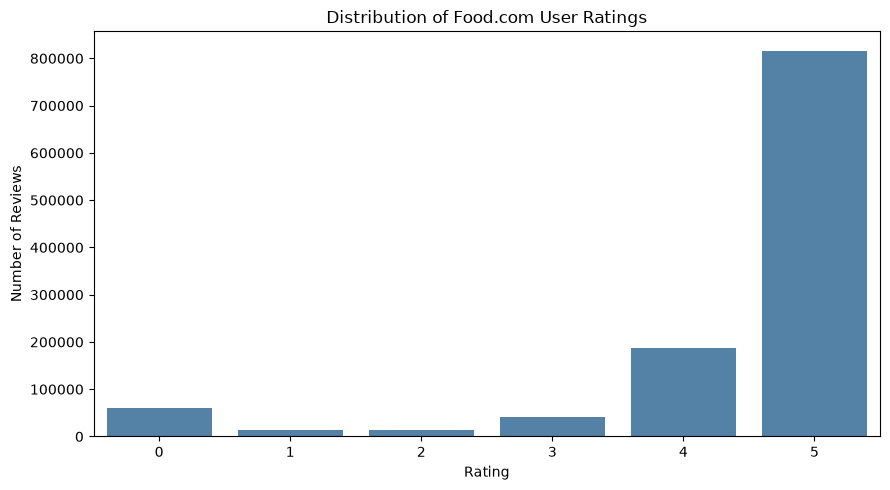

In [9]:
rating_counts = interactions["rating"].value_counts().sort_index()

plt.figure(figsize=(9, 5))

sns.barplot(
    x=rating_counts.index,
    y=rating_counts.values,
    color="steelblue",
)

plt.title("Distribution of Food.com User Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

Review counts per reviewed recipe:


count    231637.000000
mean          4.888541
std          17.532481
min           1.000000
25%           1.000000
50%           2.000000
75%           4.000000
max        1613.000000
dtype: float64

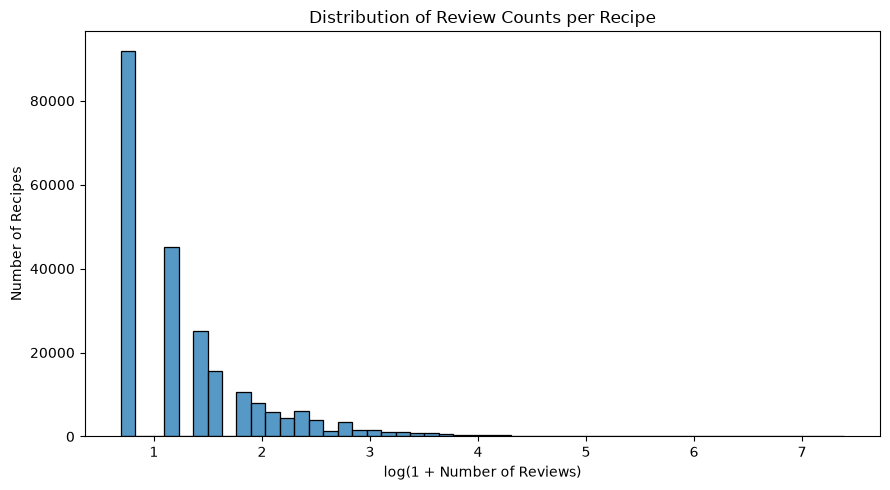

In [10]:
review_counts = interactions.groupby("recipe_id").size()

print("Review counts per reviewed recipe:")
display(review_counts.describe())

plt.figure(figsize=(9, 5))

sns.histplot(
    np.log1p(review_counts),
    bins=50,
)

plt.title("Distribution of Review Counts per Recipe")
plt.xlabel("log(1 + Number of Reviews)")
plt.ylabel("Number of Recipes")
plt.tight_layout()
plt.show()

# Recipe-Level Rating Summary

Build one record per recipe containing its metadata,
total interaction count, valid rating count, and mean
valid rating.

These statistics provide the inputs for the ranking methods.

In [11]:
import sys

project_root = DATA_PATH.resolve().parent

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from rate_my_recipe.data_preparation import RecipeDataPreparer

recipe_data_preparer = RecipeDataPreparer(
    recipes=recipes,
    interactions=interactions,
)

recipe_rating_summary = (
    recipe_data_preparer.build_recipe_rating_summary()
)

summarize_pdf(recipe_rating_summary, n=5)


Shape: (231637, 7)

Dataframe:


,recipe_id,recipe_name,preparation_time_minutes,ingredient_count,interaction_count,valid_rating_count,mean_valid_rating
0,137739,arriba baked winter squash mexican style,55,7,3,3,5.000000
1,31490,a bit different breakfast pizza,30,6,4,3,4.666667
2,112140,all in the kitchen chili,130,13,1,1,4.000000
3,59389,alouette potatoes,45,11,2,2,4.500000
4,44061,amish tomato ketchup for canning,190,8,1,1,5.000000


In [12]:
assert len(recipe_rating_summary) == len(recipes)

assert recipe_rating_summary["recipe_id"].is_unique

assert (
    recipe_rating_summary["interaction_count"].sum()
    == len(interactions)
)

assert (
    recipe_rating_summary["valid_rating_count"].sum()
    == 1_071_520
)

assert (
    recipe_rating_summary["valid_rating_count"].eq(0).sum()
    == 5_047
)

assert (
    recipe_rating_summary.loc[
        recipe_rating_summary["valid_rating_count"].eq(0),
        "mean_valid_rating",
    ].isna().all()
)

assert (
    recipe_rating_summary["valid_rating_count"]
    <= recipe_rating_summary["interaction_count"]
).all()

display(recipe_rating_summary.describe())

,recipe_id,preparation_time_minutes,ingredient_count,interaction_count,valid_rating_count,mean_valid_rating
count,231637.000000,2.316370e+05,231637.000000,231637.000000,231637.000000,226590.000000
mean,222014.708984,9.398546e+03,9.051153,4.888541,4.625859,4.580778
std,141206.635626,4.461963e+06,3.734796,17.532481,16.415246,0.629448
min,38.000000,0.000000e+00,1.000000,1.000000,0.000000,1.000000
25%,99944.000000,2.000000e+01,6.000000,1.000000,1.000000,4.333333
50%,207249.000000,4.000000e+01,9.000000,2.000000,2.000000,4.888889
75%,333816.000000,6.500000e+01,11.000000,4.000000,4.000000,5.000000
max,537716.000000,2.147484e+09,43.000000,1613.000000,1496.000000,5.000000


In [13]:
processed_data_directory = DATA_PATH / "processed"
processed_data_directory.mkdir(parents=True, exist_ok=True)

processed_recipe_summary_path = (
    processed_data_directory / "recipe_rating_summary.csv"
)

recipe_rating_summary.to_csv(
    processed_recipe_summary_path,
    index=False,
)

saved_recipe_summary = pd.read_csv(processed_recipe_summary_path)

assert len(saved_recipe_summary) == len(recipe_rating_summary)
assert saved_recipe_summary["recipe_id"].is_unique

assert (
    saved_recipe_summary["valid_rating_count"].sum()
    == recipe_rating_summary["valid_rating_count"].sum()
)

assert (
    saved_recipe_summary["mean_valid_rating"].isna().sum()
    == recipe_rating_summary["mean_valid_rating"].isna().sum()
)

print(f"Saved processed dataset to: {processed_recipe_summary_path}")
print(f"Recipes: {len(saved_recipe_summary):,}")


Saved processed dataset to: ../data/processed/recipe_rating_summary.csv
Recipes: 231,637


## Recipe Tag Index

Convert serialized Food.com tags into normalized
recipe-category assignments.

A recipe may belong to multiple categories.
Duplicate assignments are removed.

In [14]:
recipe_tag_index = recipe_data_preparer.build_recipe_tag_index()

assert not recipe_tag_index.duplicated().any()

assert recipe_tag_index["recipe_id"].isin(
    recipes["id"]
).all()

processed_recipe_tags_path = (
    processed_data_directory / "recipe_tag_index.csv"
)

recipe_tag_index.to_csv(
    processed_recipe_tags_path,
    index=False,
)

print(f"Saved: {processed_recipe_tags_path}")
print(f"Recipe-tag assignments: {len(recipe_tag_index):,}")
print(f"Unique tags: {recipe_tag_index['tag'].nunique():,}")

display(recipe_tag_index.head(10))
display(recipe_tag_index["tag"].value_counts().head(20))

Saved: ../data/processed/recipe_tag_index.csv
Recipe-tag assignments: 4,141,579
Unique tags: 551


,recipe_id,tag
0,137739,60-minutes-or-less
1,137739,time-to-make
2,137739,course
3,137739,main-ingredient
4,137739,cuisine
5,137739,preparation
6,137739,occasion
7,137739,north-american
8,137739,side-dishes
9,137739,vegetables


tag
preparation           230546
time-to-make          225326
course                218148
main-ingredient       170446
dietary               165091
easy                  126062
occasion              114145
cuisine                91165
low-in-something       85776
main-dish              71786
equipment              70436
60-minutes-or-less     69990
number-of-servings     58949
meat                   56042
30-minutes-or-less     55077
vegetables             53814
taste-mood             52143
4-hours-or-less        49497
north-american         48479
3-steps-or-less        44933
Name: count, dtype: int64